24BAD010-Anusri T
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Image dimensions: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


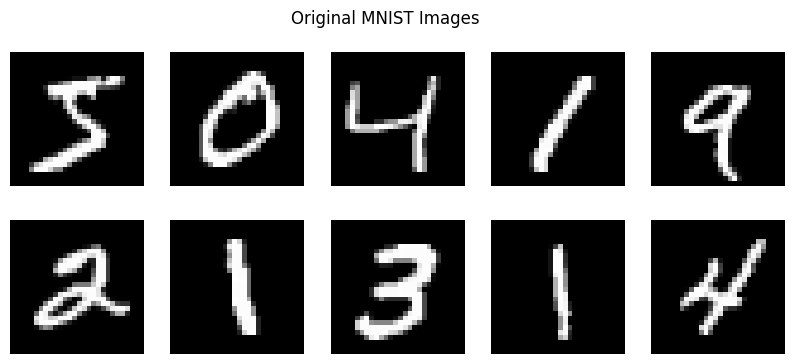

Normalized training data: (60000, 784)
Normalized testing data: (10000, 784)
Minimum value: 0.0
Maximum value: 1.0
Training input shape: (60000, 784)
Training output shape: (60000, 784)
Testing input shape: (10000, 784)
Testing output shape: (10000, 784)


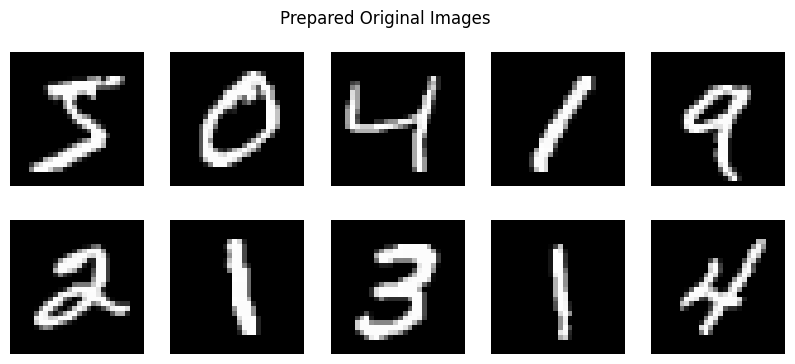

Dataset preparation completed successfully!


In [1]:
print("24BAD010-Anusri T")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Image dimensions:", x_train[0].shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')
plt.suptitle("Original MNIST Images")
plt.show()

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Normalized training data:", x_train.shape)
print("Normalized testing data:", x_test.shape)
print("Minimum value:", x_train.min())
print("Maximum value:", x_train.max())

train_input = x_train
train_output = x_train

test_input = x_test
test_output = x_test

print("Training input shape:", train_input.shape)
print("Training output shape:", train_output.shape)
print("Testing input shape:", test_input.shape)
print("Testing output shape:", test_output.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_input[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.suptitle("Prepared Original Images")
plt.show()

print("Dataset preparation completed successfully!")


24BAD010-Anusri T
AUTOENCODER MODEL SUMMARY


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

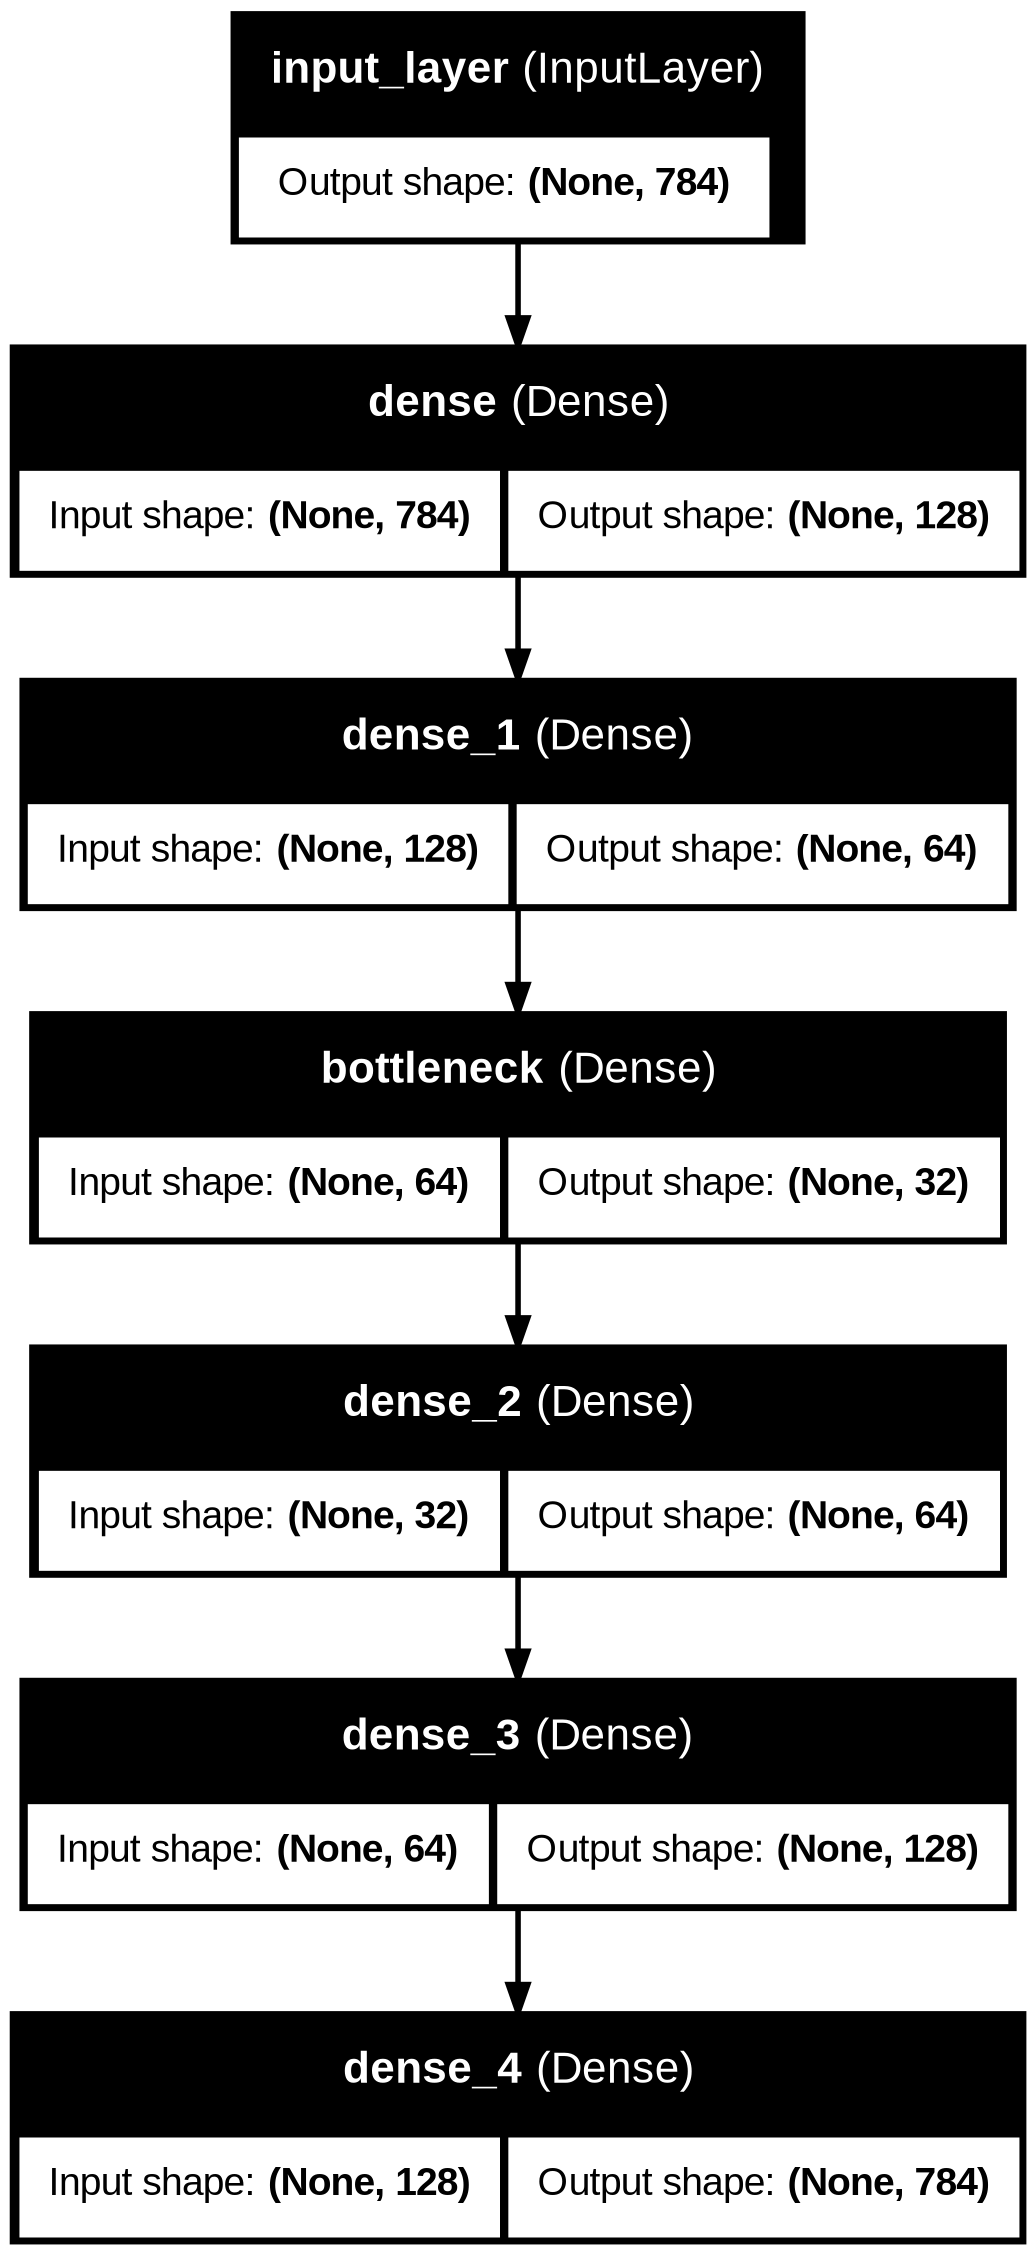

Autoencoder model created and compiled successfully!


In [2]:
print("24BAD010-Anusri T")

import tensorflow as tf
from tensorflow.keras import layers, Model

input_dim = 784
encoding_dim = 32

input_layer = layers.Input(shape=(input_dim,))

encoder = layers.Dense(128, activation='relu')(input_layer)
encoder = layers.Dense(64, activation='relu')(encoder)
bottleneck = layers.Dense(encoding_dim, activation='relu', name='bottleneck')(encoder)

decoder = layers.Dense(64, activation='relu')(bottleneck)
decoder = layers.Dense(128, activation='relu')(decoder)
output_layer = layers.Dense(784, activation='sigmoid')(decoder)

autoencoder = Model(input_layer, output_layer)

encoder_model = Model(input_layer, bottleneck)

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("AUTOENCODER MODEL SUMMARY")
autoencoder.summary()

print("\nENCODER MODEL SUMMARY")
encoder_model.summary()

tf.keras.utils.plot_model(
    autoencoder,
    to_file='autoencoder_architecture.png',
    show_shapes=True,
    show_layer_names=True
)

from IPython.display import Image, display
display(Image(filename='autoencoder_architecture.png'))

print("Autoencoder model created and compiled successfully!")


24BAD010-Anusri T
Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0108 - mae: 0.0352 - val_loss: 0.0105 - val_mae: 0.0344
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0106 - mae: 0.0348 - val_loss: 0.0104 - val_mae: 0.0342
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0104 - mae: 0.0344 - val_loss: 0.0103 - val_mae: 0.0340
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0103 - mae: 0.0341 - val_loss: 0.0103 - val_mae: 0.0341
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0102 - mae: 0.0339 - val_loss: 0.0099 - val_mae: 0.0332
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0100 - mae: 0.0335 - val_loss: 0.0098 - val_mae: 0.0330
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0099 - mae: 0.0333 - val_loss: 0.0097 - val_mae: 0.0328
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.0098 - mae: 0.0330 - val_loss: 0.0097 - val_mae: 0.0327
Epoch 9/20
235/235 ━━━━━━━━━━━

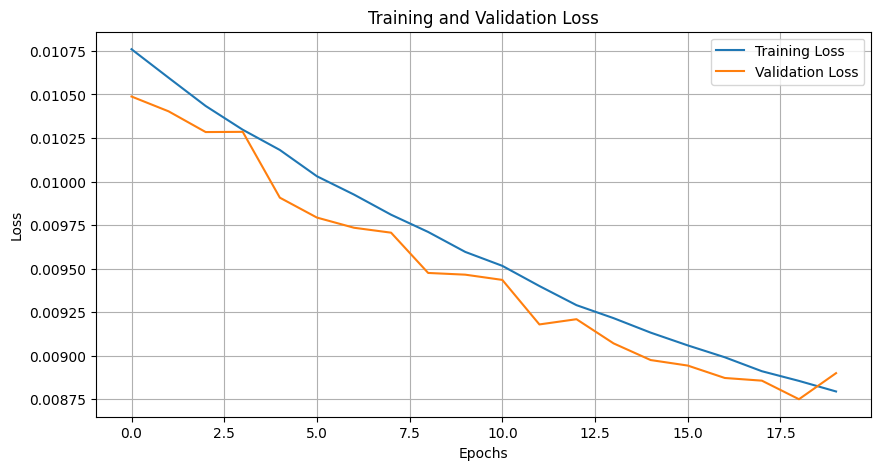

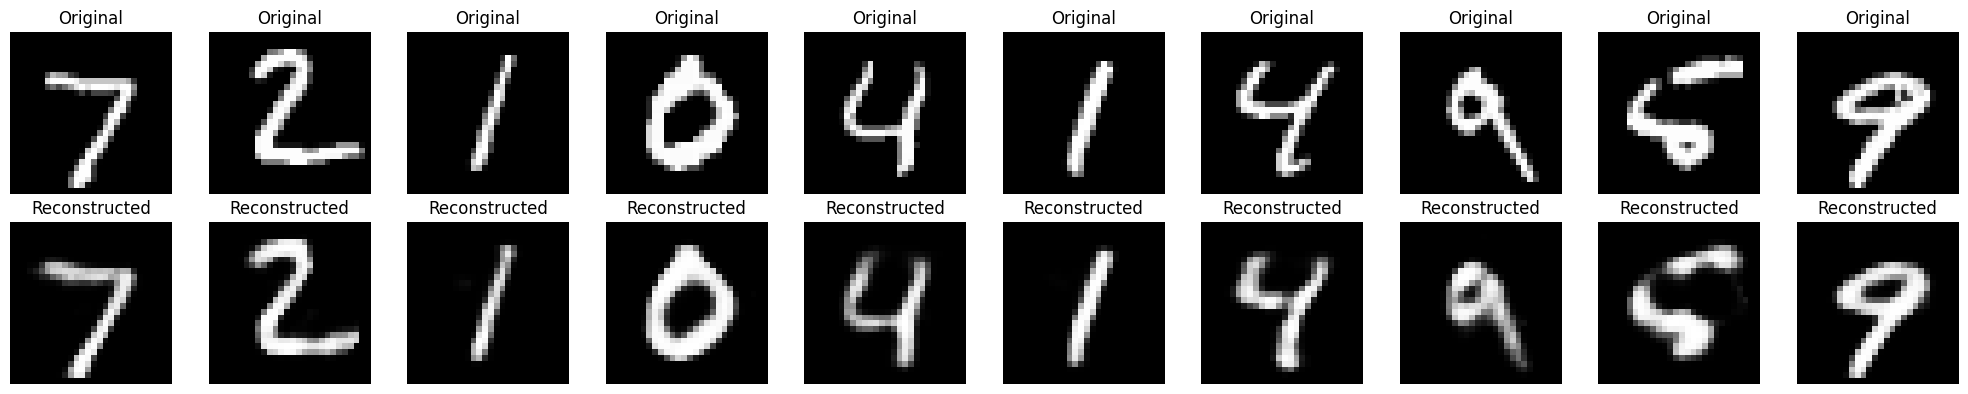

Autoencoder Training Completed Successfully!
Model Evaluation Completed Successfully!


In [4]:
print("24BAD010-Anusri T")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

EPOCHS = 20
BATCH_SIZE = 256

history = autoencoder.fit(
    train_input,
    train_output,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(test_input, test_output)
)

test_loss, test_mae = autoencoder.evaluate(
    test_input,
    test_output,
    verbose=1
)

reconstructed_images = autoencoder.predict(test_input)

mse = mean_squared_error(
    test_output.flatten(),
    reconstructed_images.flatten()
)

print("Test Loss:", test_loss)
print("Test MAE:", test_mae)
print("Reconstruction MSE:", mse)

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid()
plt.show()

n = 10

plt.figure(figsize=(20, 4))

for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(test_input[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Autoencoder Training Completed Successfully!")
print("Model Evaluation Completed Successfully!")


24BAD010-Anusri T
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Original input dimensions: (10000, 784)
Compressed representation dimensions: (10000, 32)


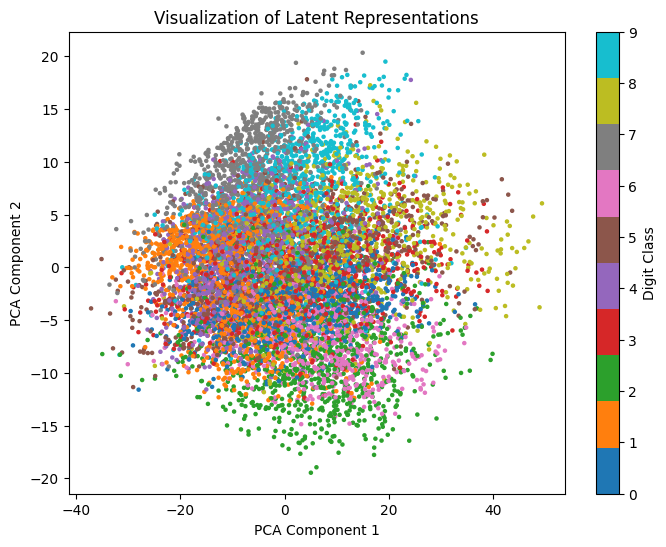

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


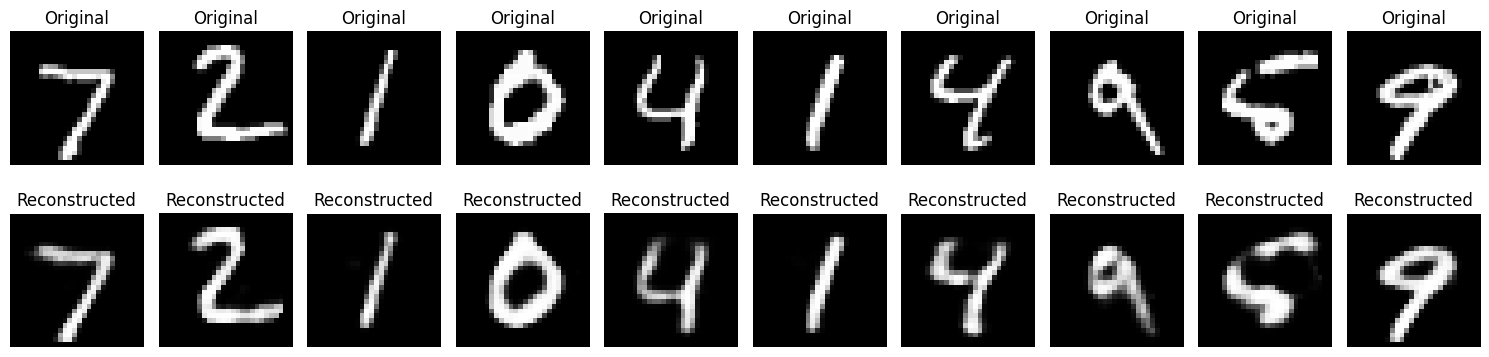

Original dimensions: 784
Compressed dimensions: 32
Dimensionality reduced from 784 to 32.
Feature extraction and reconstruction completed successfully!


In [5]:
print("24BAD010-Anusri T")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

latent_features = encoder_model.predict(test_input)

print("Original input dimensions:", test_input.shape)
print("Compressed representation dimensions:", latent_features.shape)

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))
plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test, cmap='tab10', s=5)
plt.colorbar(label='Digit Class')
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Visualization of Latent Representations")
plt.show()

reconstructed_images = autoencoder.predict(test_input)

n = 10
plt.figure(figsize=(15, 4))

for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(test_input[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Original dimensions:", test_input.shape[1])
print("Compressed dimensions:", latent_features.shape[1])
print("Dimensionality reduced from 784 to 32.")
print("Feature extraction and reconstruction completed successfully!")